# 1 / 3 — A small GPT (Transformer) from scratch

**What this notebook does, in plain words:** it trains a ~14M-parameter GPT on **TinyStories** (short, simple English stories) so that it learns to write its own. It also measures speed and memory and saves them to `results.json`; the Mamba and Jamba notebooks will be compared against these numbers.

Builds on Karpathy's `gpt_dev.ipynb`, with the upgrades used in modern LLMs: a BPE tokenizer, RoPE positions, fused QKV + `scaled_dot_product_attention`, weight tying, mixed precision, a cosine LR schedule, a KV-cache, and checkpoint/resume.

| Section | What happens |
|---|---|
| 0 | Setup, config, pre-flight checks |
| 1 | Download TinyStories → train an 8k BPE tokenizer → `train.bin` / `val.bin` |
| 2 | Data loader |
| 3 | The model, piece by piece, with tests |
| 4 | Training (checkpoints + time guard) |
| 5 | Text generation, with and without KV-cache |
| 6 | Analysis: loss curves, attention maps, speed/memory benchmarks → `results.json` |

**How to run on Kaggle:** *Settings → Accelerator → GPU T4 x2* (or P100), *Internet → On*, then **Run All**. Only one GPU is used.
**Colab:** *Runtime → Change runtime type → T4 GPU*, then Run all.

Cells marked **[shared]** will be reused unchanged by the Mamba and Jamba notebooks — only Section 3 changes.

## 0. Setup  [shared]
One `Config` holds every setting. `SMOKE_TEST=1` (environment variable) switches to a tiny model on synthetic text so the whole notebook runs on a CPU in a minute — useful for checking code changes before spending GPU quota.

In [1]:
# [shared] imports — installs tokenizers/datasets only if missing (Kaggle & Colab already have them)
import importlib.util, subprocess, sys
for pkg in ["tokenizers", "datasets"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

import os, math, time, json, glob, shutil, csv, random, contextlib
from dataclasses import dataclass, asdict, field
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

os.environ.setdefault("TOKENIZERS_PARALLELISM", "true")
SMOKE_TEST = os.environ.get("SMOKE_TEST", "0") == "1"
print("torch", torch.__version__, "| SMOKE_TEST =", SMOKE_TEST)

torch 2.11.0+cu130 | SMOKE_TEST = False


In [2]:
# [shared] configuration
def default_out_dir():
    if os.path.isdir("/kaggle/working"): return "/kaggle/working/gpt_run"
    if os.path.isdir("/content"):        return "/content/gpt_run"
    return "./gpt_run"

@dataclass
class Config:
    # data
    dataset: str = "roneneldan/TinyStories"
    vocab_size: int = 8192
    tokenizer_train_docs: int = 300_000   # stories used to learn the BPE merges
    # model
    n_layer: int = 6
    n_head: int = 6
    d_model: int = 384
    block_size: int = 512                 # training context length
    dropout: float = 0.0                  # TinyStories is big enough; no dropout needed
    pos_encoding: str = "rope"            # "rope" or "learned"
    max_pos: int = 4096                   # longest sequence RoPE supports (for benchmarks)
    use_sdpa: bool = True                 # fused attention kernel vs. hand-written
    # training
    batch_size: int = 32
    grad_accum: int = 4                   # 32 x 4 x 512 = 65,536 tokens per optimizer step
    max_tokens: int = 300_000_000
    lr: float = 1e-3
    min_lr: float = 1e-4
    warmup_steps: int = 200
    weight_decay: float = 0.1
    grad_clip: float = 1.0
    eval_interval: int = 250
    eval_iters: int = 50
    log_interval: int = 50
    time_limit_hours: float = 8.0         # save & stop cleanly before the session is killed
    seed: int = 1337
    out_dir: str = field(default_factory=default_out_dir)

    @property
    def head_dim(self): return self.d_model // self.n_head
    @property
    def tokens_per_step(self): return self.batch_size * self.grad_accum * self.block_size
    @property
    def max_steps(self): return self.max_tokens // self.tokens_per_step

cfg = Config()
if SMOKE_TEST:
    cfg = Config(vocab_size=512, tokenizer_train_docs=2000, n_layer=2, n_head=2, d_model=64,
                 block_size=64, max_pos=256, batch_size=8, grad_accum=2, max_tokens=8*2*64*60,
                 warmup_steps=5, eval_interval=20, eval_iters=5, log_interval=10,
                 out_dir="./gpt_smoke")
os.makedirs(cfg.out_dir, exist_ok=True)
print(json.dumps(asdict(cfg), indent=1))
print(f"tokens/step = {cfg.tokens_per_step:,} | max_steps = {cfg.max_steps:,}")

{
 "dataset": "roneneldan/TinyStories",
 "vocab_size": 8192,
 "tokenizer_train_docs": 300000,
 "n_layer": 6,
 "n_head": 6,
 "d_model": 384,
 "block_size": 512,
 "dropout": 0.0,
 "pos_encoding": "rope",
 "max_pos": 4096,
 "use_sdpa": true,
 "batch_size": 32,
 "grad_accum": 4,
 "max_tokens": 300000000,
 "lr": 0.001,
 "min_lr": 0.0001,
 "warmup_steps": 200,
 "weight_decay": 0.1,
 "grad_clip": 1.0,
 "eval_interval": 250,
 "eval_iters": 50,
 "log_interval": 50,
 "time_limit_hours": 8.0,
 "seed": 1337,
 "out_dir": "/kaggle/working/gpt_run"
}
tokens/step = 65,536 | max_steps = 4,577


In [3]:
# [shared] device, precision and pre-flight checks
device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cuda":
    major, minor = torch.cuda.get_device_capability()
    # bf16 needs compute capability >= 8 (A100, L4...). T4 (7.5) and P100 (6.0) use fp16 + GradScaler.
    amp_dtype = torch.bfloat16 if major >= 8 else torch.float16
    print(f"GPU: {torch.cuda.get_device_name()} (sm_{major}{minor}), "
          f"{torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB | AMP dtype: {amp_dtype}")
else:
    amp_dtype = None
    print("Running on CPU")

def autocast_ctx():
    return torch.autocast(device_type="cuda", dtype=amp_dtype) if amp_dtype else contextlib.nullcontext()

# ---- pre-flight guards: fail early with a clear message ----
problems = []
if device != "cuda" and not SMOKE_TEST:
    problems.append("No GPU found. Kaggle: Settings → Accelerator → GPU. Colab: Runtime → Change runtime type → T4 GPU.")
if cfg.d_model % cfg.n_head:
    problems.append("d_model must be divisible by n_head")
if cfg.pos_encoding == "rope" and cfg.head_dim % 2:
    problems.append("RoPE needs an even head_dim")
if cfg.vocab_size >= 2**16:
    problems.append("vocab_size must be < 65536 (tokens are stored as uint16)")
free_gb = shutil.disk_usage(cfg.out_dir).free / 1e9
if free_gb < (0.1 if SMOKE_TEST else 4):
    problems.append(f"Only {free_gb:.1f} GB free disk; need ~4 GB for data + checkpoints")
if problems:
    raise RuntimeError("Pre-flight failed:\n- " + "\n- ".join(problems))
print(f"Pre-flight OK | free disk {free_gb:.0f} GB | out_dir = {cfg.out_dir}")

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
set_seed(cfg.seed)

GPU: Tesla T4 (sm_75), 15.6 GB | AMP dtype: torch.float16
Pre-flight OK | free disk 21 GB | out_dir = /kaggle/working/gpt_run


## 1. Data: TinyStories → BPE tokenizer → token files  [shared]
**Plain words:** the model only sees integers. Karpathy used one integer per *character* (65 symbols). Here we learn a **BPE** vocabulary of 8,192 pieces: frequent chunks like `" the"` or `"ing"` become a single token, so each 512-token window holds ~4× more text.

All stories are encoded once and written to `train.bin` / `val.bin` as `uint16`. Later sessions skip this step if the files exist — either in `out_dir` or attached as a Kaggle input (*Add Input → your previous notebook's output*).

In [4]:
# [shared] find cached data, or build it
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders
EOT = "<|endoftext|>"   # separates stories

def find_cached_data():
    candidates = [os.path.join(cfg.out_dir, "data")]
    candidates += [os.path.dirname(p) for p in glob.glob("/kaggle/input/**/meta.json", recursive=True)]
    for d in candidates:
        needed = ["train.bin", "val.bin", "tokenizer.json", "meta.json"]
        if all(os.path.exists(os.path.join(d, f)) for f in needed):
            meta = json.load(open(os.path.join(d, "meta.json")))
            if meta.get("vocab_size") == cfg.vocab_size and meta.get("smoke") == SMOKE_TEST:
                return d
    return None

def synthetic_stories(n, seed=0):
    # tiny fake dataset for SMOKE_TEST only
    rng = random.Random(seed)
    names, things = ["Lily", "Tom", "Mia", "Ben", "Sara", "Max"], ["ball", "cat", "tree", "boat", "cake", "kite"]
    feels = ["happy", "sad", "excited", "sleepy"]
    out = []
    for _ in range(n):
        a, b = rng.sample(names, 2); t = rng.choice(things); f = rng.choice(feels)
        out.append(f"Once upon a time, {a} found a {t}. {a} was very {f}. {a} showed the {t} to {b}. "
                   f"{b} smiled and said, \"I like your {t}!\" They played all day.")
    return out

def load_splits():
    if SMOKE_TEST:
        return synthetic_stories(3000), synthetic_stories(300, seed=1)
    from datasets import load_dataset
    ds = load_dataset(cfg.dataset)
    return ds["train"], ds["validation"]

def iter_text_batches(source, bs=10_000, limit=None):
    n = len(source) if limit is None else min(limit, len(source))
    if isinstance(source, list):
        for i in range(0, n, bs):
            yield [t.strip() for t in source[i:i+bs]]
    else:   # Hugging Face Dataset
        src = source.select(range(n)) if limit is not None else source
        for batch in src.iter(batch_size=bs):
            yield [t.strip() for t in batch["text"]]

def train_tokenizer(train_src):
    tok = Tokenizer(models.BPE())
    tok.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
    tok.decoder = decoders.ByteLevel()
    trainer = trainers.BpeTrainer(vocab_size=cfg.vocab_size, special_tokens=[EOT], min_frequency=2,
                                  initial_alphabet=pre_tokenizers.ByteLevel.alphabet())
    def it():
        for texts in iter_text_batches(train_src, limit=cfg.tokenizer_train_docs):
            yield from texts
    tok.train_from_iterator(it(), trainer=trainer)
    return tok

def encode_to_bin(source, path, tok, eot_id):
    n_tok, n_doc, t0 = 0, 0, time.time()
    with open(path, "wb") as f:
        for texts in iter_text_batches(source):
            encs = tok.encode_batch(texts)
            arr = np.concatenate([np.array(e.ids + [eot_id], dtype=np.uint16) for e in encs])
            arr.tofile(f)
            n_tok += len(arr); n_doc += len(texts)
            if n_doc % 200_000 < len(texts):
                print(f"  {os.path.basename(path)}: {n_doc:,} stories, {n_tok/1e6:.0f}M tokens, {time.time()-t0:.0f}s")
    return n_tok

DATA_DIR = find_cached_data()
if DATA_DIR:
    print("Using cached data in", DATA_DIR)
else:
    DATA_DIR = os.path.join(cfg.out_dir, "data"); os.makedirs(DATA_DIR, exist_ok=True)
    t0 = time.time()
    train_src, val_src = load_splits()
    print(f"Loaded {len(train_src):,} train / {len(val_src):,} val stories ({time.time()-t0:.0f}s)")
    tok = train_tokenizer(train_src)
    tok.save(os.path.join(DATA_DIR, "tokenizer.json"))
    print(f"Tokenizer trained: {tok.get_vocab_size()} tokens ({time.time()-t0:.0f}s)")
    eot_id = tok.token_to_id(EOT)
    n_train = encode_to_bin(train_src, os.path.join(DATA_DIR, "train.bin"), tok, eot_id)
    n_val   = encode_to_bin(val_src,   os.path.join(DATA_DIR, "val.bin"),   tok, eot_id)
    json.dump({"vocab_size": cfg.vocab_size, "eot_id": eot_id, "n_train": n_train, "n_val": n_val,
               "smoke": SMOKE_TEST}, open(os.path.join(DATA_DIR, "meta.json"), "w"))
    print(f"Done in {time.time()-t0:.0f}s")

README.md:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

data/train-00000-of-00004-2d5a1467fff108(…): reconstructing file:   0%|          |  0.00B /  249MB            

data/train-00000-of-00004-2d5a1467fff108(…): downloading bytes:           |  0.00B            

data/train-00001-of-00004-5852b56a2bd28f(…): reconstructing file:   0%|          |  0.00B /  248MB            

data/train-00001-of-00004-5852b56a2bd28f(…): downloading bytes:           |  0.00B            

data/train-00002-of-00004-a26307300439e9(…): reconstructing file:   0%|          |  0.00B /  246MB            

... (4 outputs left out)

data/validation-00000-of-00001-869c898b5(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2119719 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/21990 [00:00<?, ? examples/s]

Loaded 2,119,719 train / 21,990 val stories (20s)



Tokenizer trained: 8192 tokens (66s)
  train.bin: 200,000 stories, 44M tokens, 45s
  train.bin: 400,000 stories, 89M tokens, 92s
  train.bin: 600,000 stories, 133M tokens, 138s
  train.bin: 800,000 stories, 177M tokens, 187s
  train.bin: 1,000,000 stories, 221M tokens, 234s
  train.bin: 1,200,000 stories, 265M tokens, 282s
  train.bin: 1,400,000 stories, 309M tokens, 331s
  train.bin: 1,600,000 stories, 352M tokens, 379s
  train.bin: 1,800,000 stories, 396M tokens, 429s
  train.bin: 2,000,000 stories, 440M tokens, 479s
Done in 580s


In [5]:
# [shared] load tokenizer + sanity checks
tok = Tokenizer.from_file(os.path.join(DATA_DIR, "tokenizer.json"))
meta = json.load(open(os.path.join(DATA_DIR, "meta.json")))
EOT_ID = meta["eot_id"]
encode = lambda s: tok.encode(s).ids
decode = lambda ids: tok.decode(list(ids))

sample = "Once upon a time, there was a little girl named Lily. She loved to play outside!"
ids = encode(sample)
assert decode(ids) == sample, "tokenizer round-trip failed"
assert tok.get_vocab_size() <= cfg.vocab_size, f"tokenizer vocab {tok.get_vocab_size()} > model vocab {cfg.vocab_size}"
if tok.get_vocab_size() < cfg.vocab_size:
    print(f"note: tokenizer learned only {tok.get_vocab_size()} tokens (fine; unused embedding rows)")
print(f"{len(sample)} chars -> {len(ids)} tokens ({len(sample)/len(ids):.1f} chars/token)")
print([decode([i]) for i in ids])
print(f"train: {meta['n_train']/1e6:.1f}M tokens | val: {meta['n_val']/1e6:.2f}M tokens")
if meta["n_train"] < cfg.max_tokens:
    print(f"note: training budget = {cfg.max_tokens/meta['n_train']:.2f} epochs over the train set")

80 chars -> 19 tokens (4.2 chars/token)
['Once', ' upon', ' a', ' time', ',', ' there', ' was', ' a', ' little', ' girl', ' named', ' Lily', '.', ' She', ' loved', ' to', ' play', ' outside', '!']
train: 466.8M tokens | val: 4.69M tokens


## 2. Data loader  [shared]
Same idea as Karpathy's `get_batch`: pick random starting points and cut out windows of `block_size` tokens. `y` is `x` shifted by one, so each position predicts the next token. The `.bin` files are memory-mapped, so nothing large is loaded into RAM.

In [6]:
# [shared]
train_data = np.memmap(os.path.join(DATA_DIR, "train.bin"), dtype=np.uint16, mode="r")
val_data   = np.memmap(os.path.join(DATA_DIR, "val.bin"),   dtype=np.uint16, mode="r")

def get_batch(split, batch_size=None, block_size=None):
    batch_size = batch_size or cfg.batch_size
    block_size = block_size or cfg.block_size
    data = train_data if split == "train" else val_data
    ix = torch.randint(len(data) - block_size - 1, (batch_size,))
    x = torch.stack([torch.from_numpy(data[i:i+block_size].astype(np.int64)) for i in ix])
    y = torch.stack([torch.from_numpy(data[i+1:i+1+block_size].astype(np.int64)) for i in ix])
    if device == "cuda":
        return x.pin_memory().to(device, non_blocking=True), y.pin_memory().to(device, non_blocking=True)
    return x, y

xb, yb = get_batch("train", batch_size=2, block_size=16)
print("x:", decode(xb[0].tolist()))
print("y:", decode(yb[0].tolist()))
assert torch.equal(xb[:, 1:], yb[:, :-1])

x:  "Beep, beep, beep!" The car says, "Well done, Ben
y: Beep, beep, beep!" The car says, "Well done, Ben.


## 3. The model
Same shape as the end of Karpathy's notebook: **embedding → N × Block → LayerNorm → lm_head**. A Block is *communication* (attention: tokens look at earlier tokens) followed by *computation* (MLP: each token thinks on its own). Each piece gets a test below.

### 3.1 RoPE — rotary position embeddings
**Plain words:** attention by itself has no idea of order. Karpathy *added* a learned position vector to each token. RoPE instead *rotates* each query and key by an angle proportional to its position. When a query at position *m* is compared with a key at position *n*, the rotations cancel except for *m − n* — so attention sees **relative distance** directly, and there is no position table to learn.

Technically: each pair of dimensions `(x₁, x₂)` is rotated by angle `pos · θᵢ`, with `θᵢ = 10000^(−2i/d)` — fast-spinning pairs encode fine position, slow ones encode coarse position.

In [7]:
def build_rope_cache(max_pos, head_dim, base=10000.0):
    inv_freq = 1.0 / (base ** (torch.arange(0, head_dim, 2).float() / head_dim))   # (hd/2,)
    angles = torch.outer(torch.arange(max_pos).float(), inv_freq)                    # (max_pos, hd/2)
    return angles.cos(), angles.sin()

def apply_rope(x, cos, sin):
    # x: (B, H, T, hd); cos/sin: (T, hd/2). Rotate each (even, odd) pair of dims.
    x1, x2 = x[..., 0::2].float(), x[..., 1::2].float()
    out = torch.stack((x1 * cos - x2 * sin, x1 * sin + x2 * cos), dim=-1).flatten(-2)
    return out.type_as(x)

# test: the q·k score depends only on the distance (m - n), not on absolute position
cos, sin = build_rope_cache(64, 16)
q, k = torch.randn(1, 1, 1, 16), torch.randn(1, 1, 1, 16)
def rope_score(m, n):
    qm = apply_rope(q, cos[m:m+1], sin[m:m+1]); kn = apply_rope(k, cos[n:n+1], sin[n:n+1])
    return (qm * kn).sum().item()
print(f"score(5,2)={rope_score(5,2):.4f}  score(40,37)={rope_score(40,37):.4f}  score(5,4)={rope_score(5,4):.4f}")
assert abs(rope_score(5, 2) - rope_score(40, 37)) < 1e-4
print("RoPE relative-position test passed")

score(5,2)=6.9978  score(40,37)=6.9978  score(5,4)=5.5838
RoPE relative-position test passed


### 3.2 Causal self-attention
Karpathy's `Head` + `MultiHeadAttention`, merged into one module:
- **One fused `qkv` matrix** instead of separate key/query/value per head — the same maths, one big matmul (faster on a GPU).
- Heads are a reshape: `(B, T, C) → (B, n_head, T, head_dim)`.
- Two implementations: `manual_attention` (exactly the notebook's `q @ kᵀ / √d → mask → softmax → @ v`) and PyTorch's fused `scaled_dot_product_attention` (SDPA), which never builds the full T×T matrix in memory. A test checks they agree.
- **KV-cache** for generation: keys/values of earlier tokens are stored, so each new token only computes its own q, k, v.

In [8]:
class CausalSelfAttention(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.n_head, self.head_dim = cfg.n_head, cfg.head_dim
        self.qkv  = nn.Linear(cfg.d_model, 3 * cfg.d_model, bias=False)
        self.proj = nn.Linear(cfg.d_model, cfg.d_model, bias=False)
        self.proj.SCALE_INIT = True             # see GPT._init_weights
        self.dropout = cfg.dropout
        self.resid_drop = nn.Dropout(cfg.dropout)
        self.use_sdpa = cfg.use_sdpa
        self.store_attn, self.last_attn = False, None   # for visualising attention maps

    def manual_attention(self, q, k, v, causal):
        att = (q @ k.transpose(-2, -1)) * (1.0 / math.sqrt(q.size(-1)))     # (B, H, Tq, Tk)
        if causal:
            Tq, Tk = q.size(-2), k.size(-2)
            mask = torch.ones(Tq, Tk, dtype=torch.bool, device=q.device).tril(diagonal=Tk - Tq)
            att = att.masked_fill(~mask, float("-inf"))
        att = F.softmax(att.float(), dim=-1).type_as(q)
        if self.store_attn:
            self.last_attn = att.detach().float().cpu()
        att = F.dropout(att, p=self.dropout, training=self.training)
        return att @ v                                                      # (B, H, Tq, hd)

    def forward(self, x, rope=None, kv_cache=None):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(C, dim=2)
        q, k, v = (t.view(B, T, self.n_head, self.head_dim).transpose(1, 2) for t in (q, k, v))

        past = 0 if (kv_cache is None or kv_cache["k"] is None) else kv_cache["k"].size(2)
        assert past == 0 or T == 1, "with a KV-cache: feed the prompt once, then one token at a time"
        if rope is not None:
            cos, sin = rope
            q = apply_rope(q, cos[past:past+T], sin[past:past+T])
            k = apply_rope(k, cos[past:past+T], sin[past:past+T])
        if kv_cache is not None:
            if past:
                k = torch.cat([kv_cache["k"], k], dim=2)
                v = torch.cat([kv_cache["v"], v], dim=2)
            kv_cache["k"], kv_cache["v"] = k, v

        causal = past == 0          # a single new token may look at everything in the cache
        if self.use_sdpa and not self.store_attn:
            y = F.scaled_dot_product_attention(q, k, v, is_causal=causal and T > 1,
                                               dropout_p=self.dropout if self.training else 0.0)
        else:
            y = self.manual_attention(q, k, v, causal)
        y = y.transpose(1, 2).contiguous().view(B, T, C)                     # re-assemble heads
        return self.resid_drop(self.proj(y))

### 3.3 MLP, Block and the full GPT
- **MLP:** `Linear(d → 4d) → GELU → Linear(4d → d)`. GELU is a smoother ReLU, used by GPT-2 onward.
- **Block:** pre-LayerNorm with residual connections — `x = x + attn(ln1(x))`, `x = x + mlp(ln2(x))` — exactly as in Karpathy's notebook.
- **Weight tying:** the input embedding and the output `lm_head` share one matrix. Fewer parameters, usually slightly better loss.
- **Init:** weights ~ N(0, 0.02); layers that write into the residual stream are scaled down by `1/√(2·n_layer)` so the stream doesn't grow with depth (GPT-2 trick).

In [9]:
class MLP(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.fc   = nn.Linear(cfg.d_model, 4 * cfg.d_model, bias=False)
        self.proj = nn.Linear(4 * cfg.d_model, cfg.d_model, bias=False)
        self.proj.SCALE_INIT = True
        self.drop = nn.Dropout(cfg.dropout)
    def forward(self, x):
        return self.drop(self.proj(F.gelu(self.fc(x))))

class Block(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.ln1, self.attn = nn.LayerNorm(cfg.d_model), CausalSelfAttention(cfg)
        self.ln2, self.mlp  = nn.LayerNorm(cfg.d_model), MLP(cfg)
    def forward(self, x, rope=None, kv_cache=None):
        x = x + self.attn(self.ln1(x), rope, kv_cache)   # communication
        x = x + self.mlp(self.ln2(x))                    # computation
        return x

class GPT(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        if cfg.pos_encoding == "learned":
            self.pos_emb = nn.Embedding(cfg.block_size, cfg.d_model)
        else:
            cos, sin = build_rope_cache(cfg.max_pos, cfg.head_dim)
            self.register_buffer("rope_cos", cos, persistent=False)
            self.register_buffer("rope_sin", sin, persistent=False)
        self.drop = nn.Dropout(cfg.dropout)
        self.blocks = nn.ModuleList([Block(cfg) for _ in range(cfg.n_layer)])
        self.ln_f = nn.LayerNorm(cfg.d_model)
        self.lm_head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        self.lm_head.weight = self.tok_emb.weight          # weight tying
        self.apply(self._init_weights)

    def _init_weights(self, m):
        if isinstance(m, nn.Linear):
            std = 0.02 * ((2 * self.cfg.n_layer) ** -0.5 if getattr(m, "SCALE_INIT", False) else 1.0)
            nn.init.normal_(m.weight, mean=0.0, std=std)
            if m.bias is not None: nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)

    @property
    def max_len(self):
        return self.cfg.block_size if self.cfg.pos_encoding == "learned" else self.cfg.max_pos

    def num_params(self):
        return sum(p.numel() for p in self.parameters())   # tied weights counted once

    def forward(self, idx, targets=None, kv_caches=None, last_only=False):
        B, T = idx.shape
        past = 0 if (kv_caches is None or kv_caches[0]["k"] is None) else kv_caches[0]["k"].size(2)
        assert past + T <= self.max_len, f"sequence length {past+T} > model limit {self.max_len}"
        x = self.tok_emb(idx)                                                 # (B, T, C)
        rope = None
        if self.cfg.pos_encoding == "learned":
            x = x + self.pos_emb(torch.arange(past, past + T, device=idx.device))
        else:
            rope = (self.rope_cos, self.rope_sin)
        x = self.drop(x)
        for i, blk in enumerate(self.blocks):
            x = blk(x, rope, None if kv_caches is None else kv_caches[i])
        x = self.ln_f(x)
        if targets is None:
            logits = self.lm_head(x[:, -1:, :] if last_only else x)           # generation needs only the last step
            return logits, None
        logits = self.lm_head(x)
        loss = F.cross_entropy(logits.float().view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

    def configure_optimizer(self, lr, weight_decay, device):
        # weight decay on matrices only; not on biases, LayerNorm gains
        params = [p for p in self.parameters() if p.requires_grad]
        decay    = [p for p in params if p.dim() >= 2]
        no_decay = [p for p in params if p.dim() < 2]
        groups = [{"params": decay, "weight_decay": weight_decay},
                  {"params": no_decay, "weight_decay": 0.0}]
        return torch.optim.AdamW(groups, lr=lr, betas=(0.9, 0.95), eps=1e-8,
                                 fused=(device == "cuda"))

    @staticmethod
    def _sample(logits, temperature, top_k):
        if temperature == 0:
            return logits.argmax(dim=-1, keepdim=True)
        logits = logits / temperature
        if top_k is not None:
            v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
            logits = logits.masked_fill(logits < v[:, [-1]], float("-inf"))
        return torch.multinomial(F.softmax(logits.float(), dim=-1), num_samples=1)

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0, top_k=None, use_cache=True, crop=True):
        if use_cache:
            assert idx.size(1) + max_new_tokens <= self.max_len, "too long for KV-cache generation"
            caches = [{"k": None, "v": None} for _ in self.blocks]
            logits, _ = self(idx, kv_caches=caches, last_only=True)          # "prefill" the prompt
            for i in range(max_new_tokens):
                nxt = self._sample(logits[:, -1, :], temperature, top_k)
                idx = torch.cat([idx, nxt], dim=1)
                if i < max_new_tokens - 1:
                    logits, _ = self(nxt, kv_caches=caches, last_only=True)  # one token in
            return idx
        # no cache: re-run the whole (cropped) sequence every step, like Karpathy's version
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.cfg.block_size:] if crop else idx
            logits, _ = self(idx_cond, last_only=True)
            idx = torch.cat([idx, self._sample(logits[:, -1, :], temperature, top_k)], dim=1)
        return idx

m_tmp = GPT(cfg)
n_emb = cfg.vocab_size * cfg.d_model
print(f"{m_tmp.num_params()/1e6:.2f}M parameters ({n_emb/1e6:.2f}M in the tied embedding)")
del m_tmp

13.77M parameters (3.15M in the tied embedding)


### 3.4 Tests
Each test checks one property we rely on. All run in full fp32 precision.
1. **Shapes** come out right.
2. **SDPA = manual attention** — the fused kernel computes the same thing as the hand-written maths.
3. **Causality** — changing a *future* token never changes predictions for earlier positions (otherwise the model could cheat by peeking).
4. **KV-cache = full forward** — incremental decoding gives the same logits as recomputing everything.
5. **Initial loss ≈ ln(vocab)** — an untrained model should be uniformly unsure: ln(8192) ≈ 9.01.
6. **Overfit one batch** — the model can memorise a tiny batch. If it can't, something is broken.

In [10]:
def run_model_tests():
    set_seed(0)
    m = GPT(cfg).to(device).eval()
    B, T = 2, min(32, cfg.block_size)
    idx = torch.randint(cfg.vocab_size, (B, T), device=device)

    # 1. shapes
    logits, _ = m(idx)
    assert logits.shape == (B, T, cfg.vocab_size); print("1 shapes ok", tuple(logits.shape))

    # 2. SDPA vs manual
    for blk in m.blocks: blk.attn.use_sdpa = False
    logits_manual, _ = m(idx)
    for blk in m.blocks: blk.attn.use_sdpa = True
    diff = (logits - logits_manual).abs().max().item()
    assert diff < 1e-4, diff; print(f"2 SDPA == manual (max diff {diff:.1e})")

    # 3. causality: change the token at position t; positions < t must not change
    t = T // 2
    idx2 = idx.clone(); idx2[:, t] = (idx2[:, t] + 1) % cfg.vocab_size
    logits2, _ = m(idx2)
    assert torch.allclose(logits[:, :t], logits2[:, :t], atol=1e-5), "future token leaked into the past!"
    assert not torch.allclose(logits[:, t], logits2[:, t]), "changed token had no effect?"
    print(f"3 causal: positions < {t} unchanged")

    # 4. KV-cache gives the same logits as a full forward pass
    if cfg.pos_encoding == "rope":
        caches = [{"k": None, "v": None} for _ in m.blocks]
        step_logits = [m(idx[:, :1], kv_caches=caches)[0]]
        for i in range(1, T):
            step_logits.append(m(idx[:, i:i+1], kv_caches=caches)[0])
        diff = (torch.cat(step_logits, dim=1) - logits).abs().max().item()
        assert diff < 1e-4, diff; print(f"4 KV-cache == full forward (max diff {diff:.1e})")

    # 5. initial loss ~ ln(V)
    x, y = get_batch("train", batch_size=8)
    _, loss = m(x, y)
    expected = math.log(cfg.vocab_size)
    assert abs(loss.item() - expected) < 0.5, (loss.item(), expected)
    print(f"5 initial loss {loss.item():.3f} vs ln(V) = {expected:.3f}")

    # 6. overfit a single small batch
    m.train()
    opt = torch.optim.AdamW(m.parameters(), lr=1e-3)
    x, y = get_batch("train", batch_size=4, block_size=min(128, cfg.block_size))
    first = None
    for i in range(150):
        _, loss = m(x, y)
        opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
        first = first or loss.item()
    assert loss.item() < 0.25 * first, (first, loss.item())
    print(f"6 overfit one batch: {first:.2f} -> {loss.item():.3f}")
    del m, opt
    if device == "cuda": torch.cuda.empty_cache()
    print("All model tests passed ✅")

run_model_tests()

1 shapes ok (2, 32, 8192)
2 SDPA == manual (max diff 2.5e-06)
3 causal: positions < 16 unchanged
4 KV-cache == full forward (max diff 1.7e-06)
5 initial loss 9.115 vs ln(V) = 9.011
6 overfit one batch: 9.13 -> 0.004
All model tests passed ✅


## 4. Training  [shared, except the model line]
**Plain words:** repeat — take a batch, measure how wrong the next-token predictions are (cross-entropy loss), nudge the weights to be less wrong.

Details that matter on a free GPU:
- **Mixed precision:** matmuls run in fp16 (2–3× faster on a T4). `GradScaler` multiplies the loss before `backward()` so tiny fp16 gradients don't round to zero.
- **Gradient accumulation:** 4 micro-batches of 32 are summed before each update → an effective batch of 65k tokens without running out of memory.
- **LR schedule:** linear warm-up for 200 steps, then cosine decay from 1e-3 to 1e-4.
- **Checkpoint + resume:** saved at every evaluation. If the session dies, attach this notebook's output as an input and run again — training continues from the last checkpoint.
- **Time guard:** saves and stops cleanly after `time_limit_hours`.

In [11]:
# [shared] checkpoint helpers
CKPT = os.path.join(cfg.out_dir, "ckpt.pt")
LOG  = os.path.join(cfg.out_dir, "log.csv")

def find_checkpoint():
    cands = [CKPT] + glob.glob("/kaggle/input/**/ckpt.pt", recursive=True)
    cands = [c for c in cands if os.path.exists(c)]
    best = None
    for c in cands:
        ck = torch.load(c, map_location="cpu", weights_only=False)
        if ck["cfg"] == asdict(cfg) and (best is None or ck["step"] > best[1]["step"]):
            best = (c, ck)
    return best

def save_checkpoint(state):
    tmp = CKPT + ".tmp"
    torch.save(state, tmp); os.replace(tmp, CKPT)    # atomic: never leaves a half-written file

def get_lr(step):
    if step < cfg.warmup_steps:
        return cfg.lr * (step + 1) / cfg.warmup_steps
    progress = (step - cfg.warmup_steps) / max(1, cfg.max_steps - cfg.warmup_steps)
    return cfg.min_lr + 0.5 * (cfg.lr - cfg.min_lr) * (1 + math.cos(math.pi * min(1.0, progress)))

@torch.no_grad()
def estimate_loss(model):
    model.eval()
    out = {}
    for split in ("train", "val"):
        losses = torch.zeros(cfg.eval_iters)
        for k in range(cfg.eval_iters):
            x, y = get_batch(split)
            with autocast_ctx():
                _, loss = model(x, y)
            losses[k] = loss.item()
        out[split] = losses.mean().item()
    model.train()
    return out

In [12]:
# build model + optimizer, resume if a checkpoint exists
set_seed(cfg.seed)
model = GPT(cfg).to(device)          # <- the only line that changes for Mamba / Jamba
optimizer = model.configure_optimizer(cfg.lr, cfg.weight_decay, device)
scaler = torch.amp.GradScaler("cuda", enabled=(amp_dtype == torch.float16))

start_step, train_time = 0, 0.0
found = find_checkpoint()
if found:
    path, ck = found
    model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optimizer"]); scaler.load_state_dict(ck["scaler"])
    start_step, train_time = ck["step"], ck["train_time"]
    log_src = os.path.join(os.path.dirname(path), "log.csv")
    if os.path.exists(log_src) and os.path.abspath(log_src) != os.path.abspath(LOG):
        shutil.copy(log_src, LOG)
    print(f"Resumed from {path} at step {start_step:,}")
    del ck
else:
    with open(LOG, "w", newline="") as f:
        csv.writer(f).writerow(["step", "tokens", "train_loss", "val_loss", "lr", "train_time_s"])
    print("Starting from scratch")
print(f"{model.num_params()/1e6:.2f}M params | steps {start_step:,} -> {cfg.max_steps:,}")

Starting from scratch
13.77M params | steps 0 -> 4,577


In [13]:
# training loop
def checkpoint_state(step):
    return {"model": model.state_dict(), "optimizer": optimizer.state_dict(), "scaler": scaler.state_dict(),
            "step": step, "train_time": train_time, "cfg": asdict(cfg)}

session_start = time.time()
model.train()
step = start_step
t_last, tokens_since = time.time(), 0
while True:
    last_step = step >= cfg.max_steps
    if step % cfg.eval_interval == 0 or last_step:
        losses = estimate_loss(model)
        with open(LOG, "a", newline="") as f:
            csv.writer(f).writerow([step, step * cfg.tokens_per_step, f"{losses['train']:.4f}",
                                    f"{losses['val']:.4f}", f"{get_lr(step):.2e}", f"{train_time:.0f}"])
        print(f"step {step:>6,} | train {losses['train']:.4f} | val {losses['val']:.4f}")
        if step > start_step or last_step:
            save_checkpoint(checkpoint_state(step))
        t_last = time.time()        # don't count eval time in throughput
    if last_step:
        break
    if time.time() - session_start > cfg.time_limit_hours * 3600:
        save_checkpoint(checkpoint_state(step))
        print(f"⏱ time limit reached — saved at step {step:,}. Re-run to resume.")
        break

    t0 = time.time()
    lr = get_lr(step)
    for g in optimizer.param_groups: g["lr"] = lr
    for _ in range(cfg.grad_accum):
        x, y = get_batch("train")
        with autocast_ctx():
            _, loss = model(x, y)
        scaler.scale(loss / cfg.grad_accum).backward()
    scaler.unscale_(optimizer)
    gnorm = torch.nn.utils.clip_grad_norm_(model.parameters(), cfg.grad_clip)
    scaler.step(optimizer); scaler.update()
    optimizer.zero_grad(set_to_none=True)
    step += 1
    train_time += time.time() - t0
    tokens_since += cfg.tokens_per_step

    if step % cfg.log_interval == 0:
        dt = time.time() - t_last
        tps = tokens_since / dt
        eta_min = (cfg.max_steps - step) * cfg.tokens_per_step / tps / 60
        mem = f" | mem {torch.cuda.max_memory_allocated()/1e9:.1f}GB" if device == "cuda" else ""
        print(f"step {step:>6,} | loss {loss.item():.4f} | lr {lr:.2e} | gnorm {gnorm:.2f} | "
              f"{tps/1e3:.0f}k tok/s | ETA {eta_min:.0f} min{mem}")
        t_last, tokens_since = time.time(), 0

torch.save({"model": model.state_dict(), "cfg": asdict(cfg)}, os.path.join(cfg.out_dir, "model_final.pt"))
print(f"Training time this run total: {train_time/60:.1f} min")

step      0 | train 8.9967 | val 8.9993
step     50 | loss 5.3748 | lr 2.50e-04 | gnorm 1.09 | 96k tok/s | ETA 52 min | mem 3.7GB
step    100 | loss 3.8050 | lr 5.00e-04 | gnorm 1.43 | 89k tok/s | ETA 55 min | mem 3.7GB
step    150 | loss 3.2663 | lr 7.50e-04 | gnorm 1.18 | 87k tok/s | ETA 55 min | mem 3.7GB
step    200 | loss 2.8605 | lr 1.00e-03 | gnorm 0.91 | 91k tok/s | ETA 53 min | mem 3.7GB
step    250 | loss 2.6371 | lr 1.00e-03 | gnorm 0.73 | 88k tok/s | ETA 54 min | mem 3.7GB
step    250 | train 2.6951 | val 2.7085
step    300 | loss 2.5343 | lr 9.99e-04 | gnorm 0.73 | 90k tok/s | ETA 52 min | mem 3.7GB
step    350 | loss 2.3621 | lr 9.97e-04 | gnorm 0.91 | 89k tok/s | ETA 52 min | mem 3.7GB
step    400 | loss 2.4214 | lr 9.95e-04 | gnorm 0.64 | 89k tok/s | ETA 51 min | mem 3.7GB
step    450 | loss 2.1896 | lr 9.93e-04 | gnorm 0.71 | 89k tok/s | ETA 50 min | mem 3.7GB
step    500 | loss 2.1561 | lr 9.90e-04 | gnorm 0.63 | 89k tok/s | ETA 50 min | mem 3.7GB
step    500 | train 

## 5. Generation
`temperature` < 1 makes the model more conservative; `top_k` only samples from the k most likely tokens. The KV-cache makes each new token cost the same small amount of work; without it the model re-reads the whole story at every step.

In [14]:
model.eval()
prompt = "Once upon a time"
idx = torch.tensor([encode(prompt)], device=device)
samples = []
for i in range(3):
    with autocast_ctx():
        out = model.generate(idx, max_new_tokens=min(200, model.max_len - idx.size(1)), temperature=0.8, top_k=50)
    text = decode(out[0].tolist()).split(EOT)[0]
    samples.append(text)
    print(f"--- sample {i+1} ---\n{text}\n")

# cached vs uncached speed for the same number of tokens
def timed_generate(use_cache, n_new):
    if device == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    with autocast_ctx():
        model.generate(idx, max_new_tokens=n_new, top_k=50, use_cache=use_cache, crop=False)
    if device == "cuda": torch.cuda.synchronize()
    return time.time() - t0
n_new = min(256, cfg.block_size - idx.size(1))
t_cache, t_nocache = timed_generate(True, n_new), timed_generate(False, n_new)
print(f"{n_new} tokens: KV-cache {n_new/t_cache:.0f} tok/s | no cache {n_new/t_nocache:.0f} tok/s")

--- sample 1 ---
Once upon a time, there was a little boy named Tim. He was a very honest boy, but sometimes he wanted to do the right thing. One day, Tim was playing in the park with his friends. He was having fun, but he was also playing with them.

Tim had an idea. He decided to throw a big, red ball at the swing. It went so high, it almost touched the sky! All his friends had gathered around to watch and cheer.

Tim put the red ball down and laughed. He laughed too. Then, he threw the ball to his friends. They all had so much fun playing together. They played until the sun went down, and then Tim went home. He was very happy.Once upon a time, there was a little bird named Tim. Tim liked to eat waffles. One day, Tim's mom made waffles for breakfast. Tim was very happy.

Tim saw a big waffle on the table. He thought, "I want

--- sample 2 ---
Once upon a time, there was a little boy named Timmy. Timmy loved to play with his toys and run around outside. One day, Timmy's mom asked him 

## 6. Analysis  [shared]
### 6.1 Loss curves
Train and val loss should fall together. A growing gap means overfitting (unlikely here — TinyStories is large).

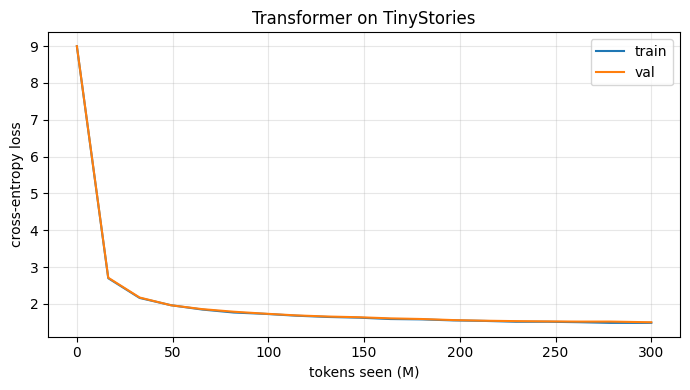

final: {'train': 1.4835, 'val': 1.4991}


In [15]:
rows = list(csv.DictReader(open(LOG)))
tok_m = [int(r["tokens"]) / 1e6 for r in rows]
plt.figure(figsize=(7, 4))
plt.plot(tok_m, [float(r["train_loss"]) for r in rows], label="train")
plt.plot(tok_m, [float(r["val_loss"]) for r in rows], label="val")
plt.xlabel("tokens seen (M)"); plt.ylabel("cross-entropy loss"); plt.title("Transformer on TinyStories")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(os.path.join(cfg.out_dir, "loss_curve.png"), dpi=120); plt.show()
final_losses = {"train": float(rows[-1]["train_loss"]), "val": float(rows[-1]["val_loss"])}
print("final:", final_losses)

### 6.2 Attention maps
Each square shows, for every token (row), how much it attends to each earlier token (column). Look for heads that focus on the **previous token**, on the **first token** (a "resting" spot), or on a **matching earlier word** (e.g. a name mentioned before). Mamba has no such map — this is one thing you lose.

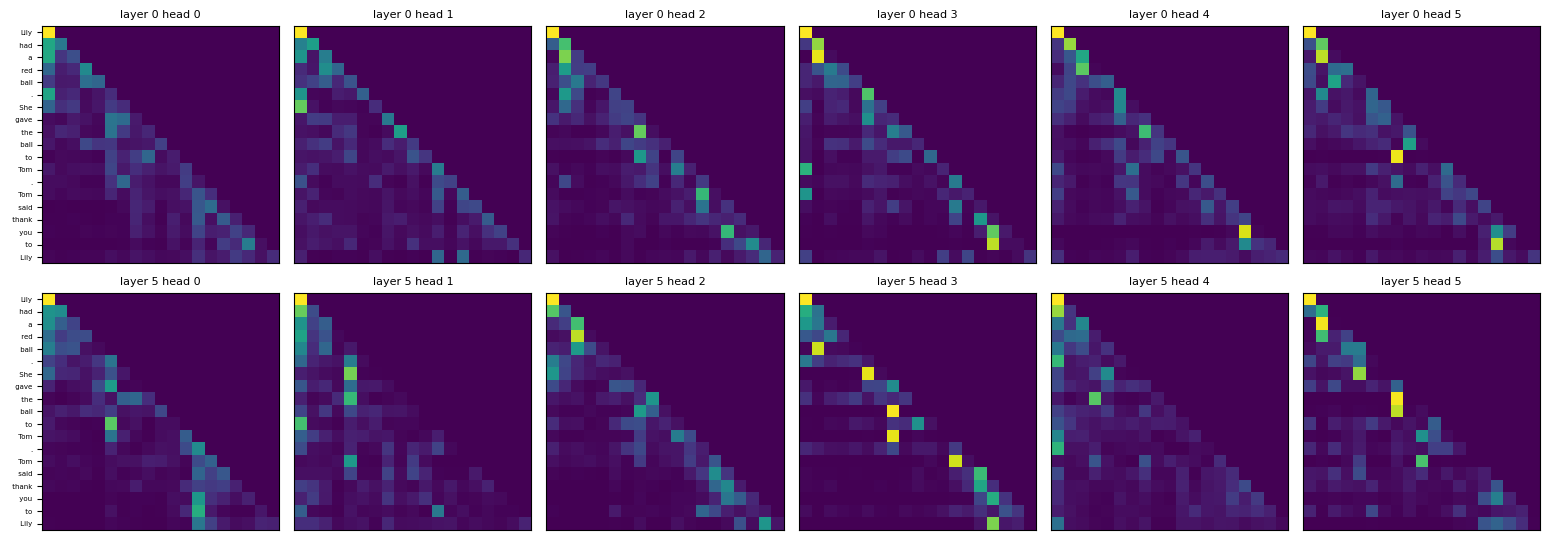

In [16]:
sentence = "Lily had a red ball. She gave the ball to Tom. Tom said thank you to Lily"
ids = encode(sentence)
labels = [decode([i]) for i in ids]
for blk in model.blocks: blk.attn.store_attn = True
with torch.no_grad():
    model(torch.tensor([ids], device=device))
for blk in model.blocks: blk.attn.store_attn = False

layers = sorted({0, cfg.n_layer - 1})
fig, axes = plt.subplots(len(layers), cfg.n_head, figsize=(2.6 * cfg.n_head, 2.8 * len(layers)), squeeze=False)
for r, li in enumerate(layers):
    att = model.blocks[li].attn.last_attn[0]          # (H, T, T)
    for h in range(cfg.n_head):
        ax = axes[r][h]; ax.imshow(att[h], cmap="viridis", vmin=0, vmax=1)
        ax.set_title(f"layer {li} head {h}", fontsize=8); ax.set_xticks([]); ax.set_yticks([])
        if h == 0:
            ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels, fontsize=5)
plt.tight_layout(); plt.savefig(os.path.join(cfg.out_dir, "attention_maps.png"), dpi=120); plt.show()

### 6.3 Benchmarks: how cost grows with sequence length
These are the numbers Mamba and Jamba will be compared against.
- **Training:** a fixed number of tokens per batch (shorter sequences → more of them) at lengths 256 → 4096. With **manual** attention the T×T score matrix makes memory grow with T². **SDPA** avoids storing it, but the compute still grows with T².
- **Generation:** time and memory to generate N tokens. The KV-cache grows linearly with N: `2 × layers × N × d_model` numbers.

In [17]:
# [shared] training-throughput benchmark
def bench_train(T, use_sdpa, tokens_per_batch, iters=5, warmup=2):
    bcfg = Config(**{**asdict(cfg), "use_sdpa": use_sdpa, "max_pos": max(cfg.max_pos, T), "dropout": 0.0})
    m = GPT(bcfg).to(device)               # <- swap for Mamba / Jamba
    opt = m.configure_optimizer(1e-4, 0.0, device)
    sc = torch.amp.GradScaler("cuda", enabled=(amp_dtype == torch.float16))
    B = max(1, tokens_per_batch // T)
    x = torch.randint(cfg.vocab_size, (B, T), device=device); y = torch.randint(cfg.vocab_size, (B, T), device=device)
    try:
        if device == "cuda": torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
        for i in range(warmup + iters):
            if i == warmup:
                if device == "cuda": torch.cuda.synchronize()
                t0 = time.time()
            with autocast_ctx():
                _, loss = m(x, y)
            sc.scale(loss).backward(); sc.step(opt); sc.update(); opt.zero_grad(set_to_none=True)
        if device == "cuda": torch.cuda.synchronize()
        tps = B * T * iters / (time.time() - t0)
        mem = round(torch.cuda.max_memory_allocated() / 1e9, 2) if device == "cuda" else None
        return {"T": T, "batch": B, "tok_per_s": round(tps), "peak_mem_gb": mem}
    except torch.OutOfMemoryError:
        return {"T": T, "batch": B, "tok_per_s": None, "peak_mem_gb": "OOM"}
    finally:
        del m, opt
        if device == "cuda": torch.cuda.empty_cache()

lengths = [32, 64, 128] if SMOKE_TEST else [256, 512, 1024, 2048, 4096]
if cfg.pos_encoding == "learned":
    lengths = [T for T in lengths if T <= cfg.block_size]
tokens_per_batch = 1024 if SMOKE_TEST else 16384
train_bench = {"sdpa": [], "manual": []}
for name, flag in (("sdpa", True), ("manual", False)):
    for T in lengths:
        r = bench_train(T, flag, tokens_per_batch); train_bench[name].append(r)
        print(f"{name:6s} T={T:5d} B={r['batch']:3d} | {str(r['tok_per_s']):>8} tok/s | peak {r['peak_mem_gb']} GB")

sdpa   T=  256 B= 64 |    89934 tok/s | peak 4.08 GB
sdpa   T=  512 B= 32 |    85861 tok/s | peak 4.08 GB
sdpa   T= 1024 B= 16 |    79945 tok/s | peak 4.08 GB
sdpa   T= 2048 B=  8 |    69294 tok/s | peak 4.08 GB
sdpa   T= 4096 B=  4 |    54412 tok/s | peak 4.08 GB
manual T=  256 B= 64 |    67382 tok/s | peak 4.84 GB
manual T=  512 B= 32 |    53852 tok/s | peak 5.74 GB
manual T= 1024 B= 16 |    38402 tok/s | peak 7.56 GB
manual T= 2048 B=  8 |    24221 tok/s | peak 11.45 GB
manual T= 4096 B=  4 |     None tok/s | peak OOM GB


In [18]:
# [shared] generation benchmark: N new tokens from a 1-token prompt
def bench_generate(n_new, use_cache):
    start = torch.tensor([[EOT_ID]], device=device)
    if device == "cuda": torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats(); torch.cuda.synchronize()
    t0 = time.time()
    with autocast_ctx():
        model.generate(start, max_new_tokens=n_new, top_k=50, use_cache=use_cache, crop=False)
    if device == "cuda": torch.cuda.synchronize()
    dt = time.time() - t0
    mem = round(torch.cuda.max_memory_allocated() / 1e9, 3) if device == "cuda" else None
    return {"N": n_new, "tok_per_s": round(n_new / dt, 1), "peak_mem_gb": mem}

gen_lengths = [16, 32, 64] if SMOKE_TEST else [128, 256, 512, 1024, 2048]
gen_lengths = [n for n in gen_lengths if n < model.max_len]
bytes_per = 2 if amp_dtype else 4
gen_bench = {"cache": [], "no_cache": []}
model.eval()
for n in gen_lengths:
    for name, flag in (("cache", True), ("no_cache", False)):
        r = bench_generate(n, flag)
        if name == "cache":
            r["kv_cache_mb"] = round(2 * cfg.n_layer * n * cfg.d_model * bytes_per / 1e6, 2)
        gen_bench[name].append(r)
        print(f"N={n:5d} {name:8s} | {r['tok_per_s']:>8} tok/s | peak {r['peak_mem_gb']} GB"
              + (f" | KV-cache {r['kv_cache_mb']} MB" if name == "cache" else ""))

N=  128 cache    |    166.7 tok/s | peak 0.485 GB | KV-cache 1.18 MB
N=  128 no_cache |    172.2 tok/s | peak 0.485 GB
N=  256 cache    |    170.5 tok/s | peak 0.486 GB | KV-cache 2.36 MB
N=  256 no_cache |    172.3 tok/s | peak 0.486 GB
N=  512 cache    |    168.0 tok/s | peak 0.489 GB | KV-cache 4.72 MB
N=  512 no_cache |    166.9 tok/s | peak 0.49 GB
N= 1024 cache    |    165.5 tok/s | peak 0.494 GB | KV-cache 9.44 MB
N= 1024 no_cache |    164.9 tok/s | peak 0.496 GB
N= 2048 cache    |    171.4 tok/s | peak 0.507 GB | KV-cache 18.87 MB
N= 2048 no_cache |    157.4 tok/s | peak 0.507 GB


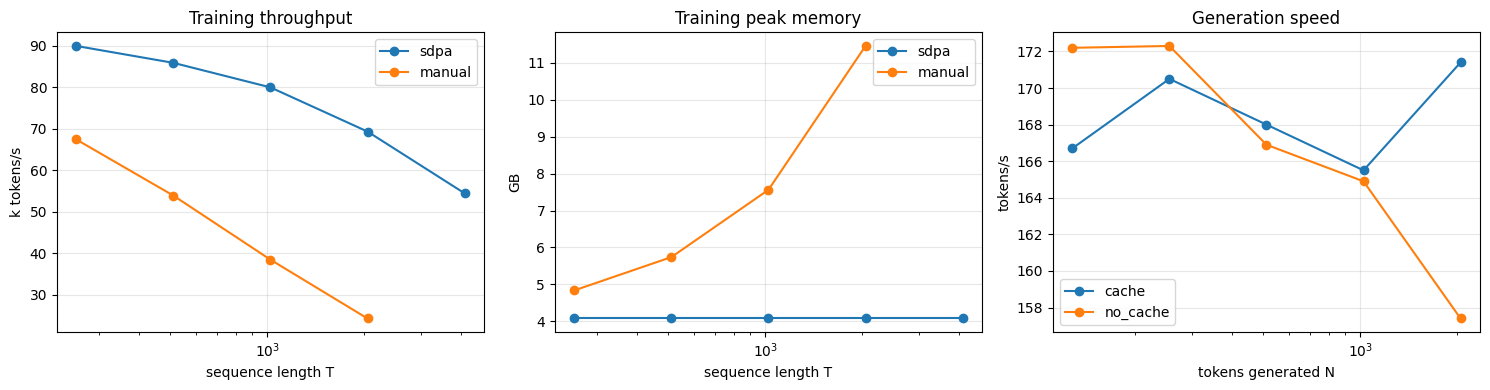

In [19]:
# [shared] plots
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for name in ("sdpa", "manual"):
    pts = [r for r in train_bench[name] if r["tok_per_s"]]
    ax[0].plot([r["T"] for r in pts], [r["tok_per_s"] / 1e3 for r in pts], "o-", label=name)
    if device == "cuda":
        ax[1].plot([r["T"] for r in pts], [r["peak_mem_gb"] for r in pts], "o-", label=name)
ax[0].set(xscale="log", xlabel="sequence length T", ylabel="k tokens/s", title="Training throughput")
ax[1].set(xscale="log", xlabel="sequence length T", ylabel="GB", title="Training peak memory")
for name in ("cache", "no_cache"):
    ax[2].plot([r["N"] for r in gen_bench[name]], [r["tok_per_s"] for r in gen_bench[name]], "o-", label=name)
ax[2].set(xscale="log", xlabel="tokens generated N", ylabel="tokens/s", title="Generation speed")
for a in ax:
    if a.lines: a.legend()
    a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(os.path.join(cfg.out_dir, "benchmarks.png"), dpi=120); plt.show()

In [20]:
# [shared] save everything the Mamba / Jamba notebooks will compare against
results = {
    "model": "transformer",
    "config": asdict(cfg),
    "n_params": model.num_params(),
    "tokens_trained": min(step, cfg.max_steps) * cfg.tokens_per_step,
    "train_time_min": round(train_time / 60, 1),
    "final_loss": final_losses,
    "gpu": torch.cuda.get_device_name() if device == "cuda" else "cpu",
    "amp_dtype": str(amp_dtype),
    "train_benchmark": train_bench,
    "generation_benchmark": gen_bench,
    "samples": samples,
}
with open(os.path.join(cfg.out_dir, "results.json"), "w") as f:
    json.dump(results, f, indent=1, allow_nan=False)
print("saved", os.path.join(cfg.out_dir, "results.json"))
print(sorted(os.listdir(cfg.out_dir)))

saved /kaggle/working/gpt_run/results.json
['attention_maps.png', 'benchmarks.png', 'ckpt.pt', 'data', 'log.csv', 'loss_curve.png', 'model_final.pt', 'results.json']


## What to look at before moving on to Mamba
- **Final val loss** — the number Mamba/Jamba have to match with the same parameter count and token budget.
- **Training memory vs T** — manual attention grows ~quadratically; SDPA grows much more slowly but compute still scales with T².
- **Generation** — with a cache, speed stays roughly flat but the cache grows linearly with N; without it, speed collapses as N grows. Mamba's selling point is flat speed **and** flat memory.
- **Attention maps** — find a "previous-token" head and a head that looks back at an earlier mention of a name. That second kind of lookup is what Mamba finds hard.

**Before the Mamba notebook:** save this notebook's output (Kaggle: *Save Version → Save & Run All*). The Mamba notebook will reuse `data/` and read this `results.json`.